# Teste com modelo XGBoost

## Import e Separação dos Dados

In [1]:
caminho = '../'

In [2]:
import pandas as pd
#Importar conjuntos de dados

df_dengue = pd.read_csv(caminho + 'database/Dengue.csv')
df_malaria= pd.read_csv(caminho + 'database/Malaria.csv')
df_shared = pd.read_csv(caminho + 'database/Shared.csv')

print(df_dengue.columns)
print(df_dengue['Result'].value_counts())

print(df_malaria.columns)
print(df_malaria['Result'].value_counts())

print(df_shared.columns)
print(df_shared['Result'].value_counts())

Index(['Hemoglobin(Hb%)', 'Total WBC count(/cumm)', 'Neutrophils',
       'Lymphocytes', 'Total Cir.Eosinophils', 'HTC/PCV(%)', 'MCH(pg)',
       'MCHC(g/dl)', 'RDW-CV(%)', 'Platelet Count', 'Result', 'tipo'],
      dtype='object')
Result
0    928
1    671
Name: count, dtype: int64
Index(['Hemoglobin(Hb%)', 'Total WBC count(/cumm)', 'Neutrophils',
       'Lymphocytes', 'Total Cir.Eosinophils', 'HTC/PCV(%)', 'MCH(pg)',
       'MCHC(g/dl)', 'RDW-CV(%)', 'Platelet Count', 'Result', 'tipo'],
      dtype='object')
Result
0    878
1    826
Name: count, dtype: int64
Index(['Hemoglobin(Hb%)', 'Total WBC count(/cumm)', 'Neutrophils',
       'Lymphocytes', 'Total Cir.Eosinophils', 'HTC/PCV(%)', 'MCH(pg)',
       'MCHC(g/dl)', 'RDW-CV(%)', 'Platelet Count', 'Result'],
      dtype='object')
Result
1    242
0    242
Name: count, dtype: int64


In [3]:
# Algumas coisinhas
tipo = df_dengue['tipo'].copy()

X = df_dengue.drop(columns=['Result', 'tipo'], axis=1).copy()
y = df_dengue['Result'].copy()

In [4]:
# Features e Labels
X_train = X[tipo == 'treino']
X_test  = X[tipo == 'teste']
X_val   = df_malaria.drop(columns=['Result', 'tipo'], axis=1).copy()
X_shared= df_shared.drop(columns=['Result'], axis=1).copy()

y_train = y[tipo == 'treino']
y_test  = y[tipo == 'teste']
y_val   = df_malaria['Result'].copy()
y_shared= df_shared['Result'].copy()

print(X_train.shape, X_test.shape, X_val.shape)
print(y_train.shape, y_test.shape, y_val.shape)

(959, 10) (640, 10) (1704, 10)
(959,) (640,) (1704,)


In [5]:
# Normalizar e Padronizar conjunto de dados
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scaler_mim_max = MinMaxScaler()
scaler_mim_max.set_output(transform="pandas")

# Com MinMax Scaler
X_train = scaler_mim_max.fit_transform(X_train)
X_test  = scaler_mim_max.transform(X_test)
X_val   = scaler_mim_max.transform(X_val)
X_shared= scaler_mim_max.transform(X_shared)

## Testar no XGBoost Default

=== MÉTRICAS DE DESEMPENHO ===

Acurácia: 0.8594
Precisão: 0.8557
Recall:   0.8634
F1-Score: 0.8576
MCC:      0.7190
AUC:      0.9306
--------------------------------------------------


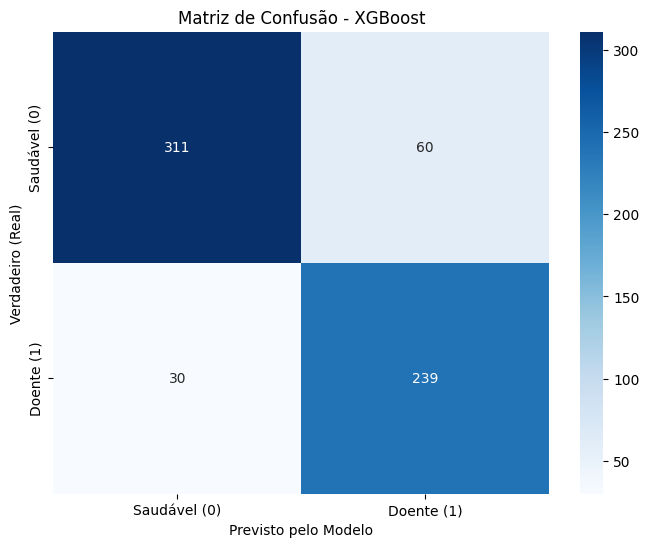

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import (classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             matthews_corrcoef, confusion_matrix)

# Modelo
xgboost = xgb.XGBClassifier(n_estimators=100, random_state=14)
xgboost.fit(X_train, y_train)

# Fazendo as Previsões
y_pred_def = xgboost.predict(X_test)
y_prob_def = xgboost.predict_proba(X_test)[:, 1]

# Métricas
acuracia_def = accuracy_score(y_test, y_pred_def)
precisao_def = precision_score(y_test, y_pred_def, average='macro')
recall_def   = recall_score(y_test, y_pred_def, average='macro')
f1_def       = f1_score(y_test, y_pred_def, average='macro')
mcc_def      = matthews_corrcoef(y_test, y_pred_def)

# O AUC binário recebe as classes reais e as probabilidades diretamente
auc = roc_auc_score(y_test, y_prob_def)

# Exibindo os Resultados
print("=== MÉTRICAS DE DESEMPENHO ===\n")
print(f"Acurácia: {acuracia_def:.4f}")
print(f"Precisão: {precisao_def:.4f}")
print(f"Recall:   {recall_def:.4f}")
print(f"F1-Score: {f1_def:.4f}")
print(f"MCC:      {mcc_def:.4f}")
print(f"AUC:      {auc:.4f}")
print("-" * 50)


# 5. Plotando a Matriz de Confusão
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_def)

# Labels ajustados exclusivamente para as duas doenças
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])

plt.title('Matriz de Confusão - XGBoost')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

## Otimização de Hiperparâmetros

In [7]:
import optuna
import xgboost as xgb
from sklearn.model_selection import cross_val_score

def objective(trial):
    # Hiperparâmetros recomendados para XGBoost
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'objective': 'binary:logistic',
        'eval_metric': 'mlogloss',
        'n_jobs': -1,
        'random_state': 14
    }

    # Inicializa o classificador
    clf = xgb.XGBClassifier(**params)

    # Cross-validation
    score = cross_val_score(clf, X_train, y_train.values.ravel(), scoring='f1_macro', cv=5).mean()
    return score

# Criando e executando
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f"Melhor pontuação: {study.best_value:.4f}")
print("Melhores parâmetros:")
print(study.best_params)

# Treinando o modelo final com os melhores parâmetros encontrados
best_xgb = xgb.XGBClassifier(**study.best_params, objective='binary:logistic', n_jobs=-1, random_state=14)
best_xgb.fit(X_train, y_train.values.ravel())

c:\Users\renan\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-07-27 12:40:25,388] A new study created in memory with name: no-name-3bf66fa0-6fb2-42f6-ab4e-e6598f1956ea
Best trial: 1. Best value: 0.885546:   4%|▍         | 2/50 [00:00<00:08,  5.36it/s]

[I 2026-07-27 12:40:25,593] Trial 0 finished with value: 0.8788565926668659 and parameters: {'n_estimators': 104, 'max_depth': 7, 'learning_rate': 0.23876399597718614, 'subsample': 0.5840258252423904, 'colsample_bytree': 0.777560890765664, 'gamma': 2.833886035054048}. Best is trial 0 with value: 0.8788565926668659.
[I 2026-07-27 12:40:25,764] Trial 1 finished with value: 0.8855463241057752 and parameters: {'n_estimators': 83, 'max_depth': 7, 'learning_rate': 0.25279360435928494, 'subsample': 0.9970240139836353, 'colsample_bytree': 0.7895246358229451, 'gamma': 2.8584601327475196}. Best is trial 1 with value: 0.8855463241057752.


Best trial: 2. Best value: 0.888891:   6%|▌         | 3/50 [00:00<00:11,  4.25it/s]

[I 2026-07-27 12:40:26,057] Trial 2 finished with value: 0.8888914799052727 and parameters: {'n_estimators': 140, 'max_depth': 6, 'learning_rate': 0.03295245686727504, 'subsample': 0.7091503467164995, 'colsample_bytree': 0.78839968609355, 'gamma': 3.8981540976396682}. Best is trial 2 with value: 0.8888914799052727.


Best trial: 3. Best value: 0.891923:   8%|▊         | 4/50 [00:00<00:09,  4.62it/s]

[I 2026-07-27 12:40:26,245] Trial 3 finished with value: 0.891923271549367 and parameters: {'n_estimators': 102, 'max_depth': 7, 'learning_rate': 0.13737831315980326, 'subsample': 0.804042497052047, 'colsample_bytree': 0.5518913503822949, 'gamma': 3.8547916594521614}. Best is trial 3 with value: 0.891923271549367.


... (81 outputs left out)

[I 2026-07-27 12:40:39,847] Trial 48 finished with value: 0.8899208663216797 and parameters: {'n_estimators': 292, 'max_depth': 5, 'learning_rate': 0.015068284599741036, 'subsample': 0.548314132838372, 'colsample_bytree': 0.7155818396065242, 'gamma': 3.6463485745259914}. Best is trial 17 with value: 0.8983031409609353.


Best trial: 17. Best value: 0.898303: 100%|██████████| 50/50 [00:14<00:00,  3.40it/s]

[I 2026-07-27 12:40:40,076] Trial 49 finished with value: 0.8952135247445664 and parameters: {'n_estimators': 103, 'max_depth': 6, 'learning_rate': 0.05273195876769521, 'subsample': 0.9036025508340565, 'colsample_bytree': 0.6522090287084306, 'gamma': 4.722349768050004}. Best is trial 17 with value: 0.8983031409609353.
Melhor pontuação: 0.8983
Melhores parâmetros:
{'n_estimators': 50, 'max_depth': 4, 'learning_rate': 0.023629964368436052, 'subsample': 0.9913950511500289, 'colsample_bytree': 0.6921228536521452, 'gamma': 3.21845817389855}


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.6921228536521452
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [8]:
fig = optuna.visualization.plot_param_importances(study)
fig.show()

fig = optuna.visualization.plot_optimization_history(study)
fig.show()

=== MÉTRICAS DE DESEMPENHO ===

Acurácia: 0.8906
Precisão: 0.8938
Recall:   0.9036
F1-Score: 0.8902
MCC:      0.7974
AUC:      0.9292
--------------------------------------------------


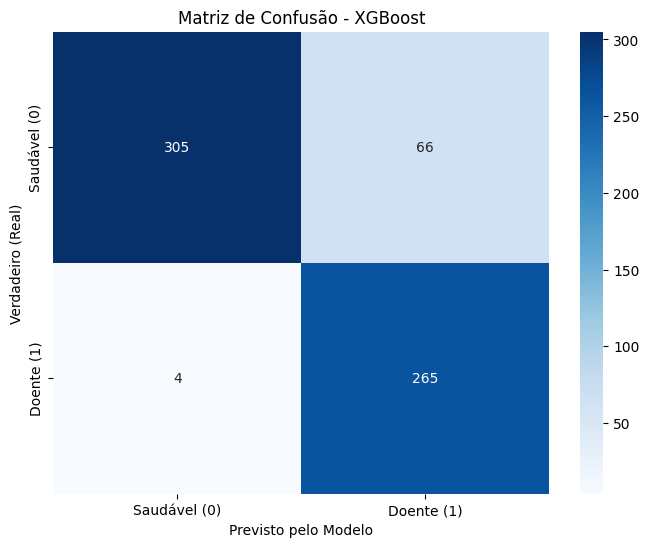

In [9]:
# Fazendo as Previsões
y_pred_best = best_xgb.predict(X_test)
y_prob_best = best_xgb.predict_proba(X_test)[:, 1]

# Métricas
acuracia_best = accuracy_score(y_test, y_pred_best)
precisao_best = precision_score(y_test, y_pred_best, average='macro')
recall_best   = recall_score(y_test, y_pred_best, average='macro')
f1_best       = f1_score(y_test, y_pred_best, average='macro')
mcc_best      = matthews_corrcoef(y_test, y_pred_best)

# O AUC binário recebe as classes reais e as probabilidades diretamente
auc = roc_auc_score(y_test, y_prob_best)

# Exibindo os Resultados
print("=== MÉTRICAS DE DESEMPENHO ===\n")
print(f"Acurácia: {acuracia_best:.4f}")
print(f"Precisão: {precisao_best:.4f}")
print(f"Recall:   {recall_best:.4f}")
print(f"F1-Score: {f1_best:.4f}")
print(f"MCC:      {mcc_best:.4f}")
print(f"AUC:      {auc:.4f}")
print("-" * 50)


# 5. Plotando a Matriz de Confusão
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_best)

# Labels ajustados exclusivamente para as duas doenças
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])

plt.title('Matriz de Confusão - XGBoost')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

# Validação Externa

=== MÉTRICAS DE DESEMPENHO ===

Acurácia: 0.6303
Precisão: 0.6313
Recall:   0.6279
F1-Score: 0.6267
MCC:      0.2592
AUC:      0.7079
--------------------------------------------------


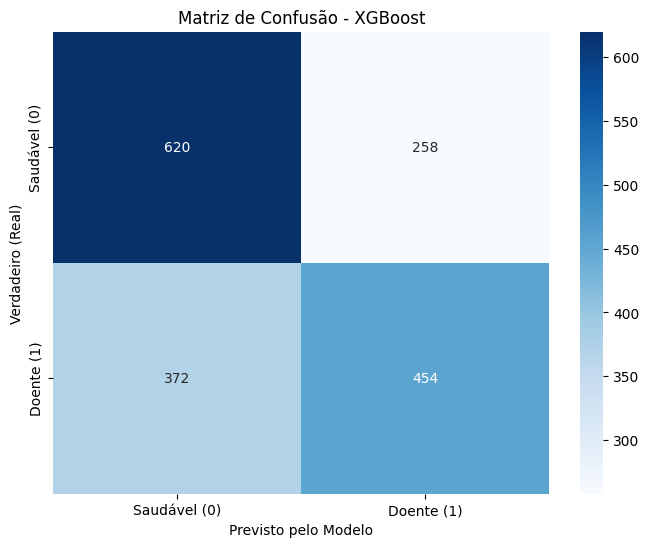

In [10]:
# Fazendo as Previsões
y_pred_val = best_xgb.predict(X_val)
y_prob_val = best_xgb.predict_proba(X_val)[:, 1]

# Métricas
acuracia_val = accuracy_score(y_val, y_pred_val)
precisao_val = precision_score(y_val, y_pred_val, average='macro')
recall_val   = recall_score(y_val, y_pred_val, average='macro')
f1_val       = f1_score(y_val, y_pred_val, average='macro')
mcc_val      = matthews_corrcoef(y_val, y_pred_val)

# O AUC binário recebe as classes reais e as probabilidades diretamente
auc = roc_auc_score(y_val, y_prob_val)

# Exibindo os Resultados
print("=== MÉTRICAS DE DESEMPENHO ===\n")
print(f"Acurácia: {acuracia_val:.4f}")
print(f"Precisão: {precisao_val:.4f}")
print(f"Recall:   {recall_val:.4f}")
print(f"F1-Score: {f1_val:.4f}")
print(f"MCC:      {mcc_val:.4f}")
print(f"AUC:      {auc:.4f}")
print("-" * 50)


# 5. Plotando a Matriz de Confusão
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_val, y_pred_val)

# Labels ajustados exclusivamente para as duas doenças
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])

plt.title('Matriz de Confusão - XGBoost')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

=== VALIDAÇÃO EXTERNA SHARED ===

Acurácia: 0.5021
Precisão: 0.5021
Recall: 0.5021
F1-Score: 0.4977
MCC: 0.0042
AUC: 0.5405
--------------------------------------------------


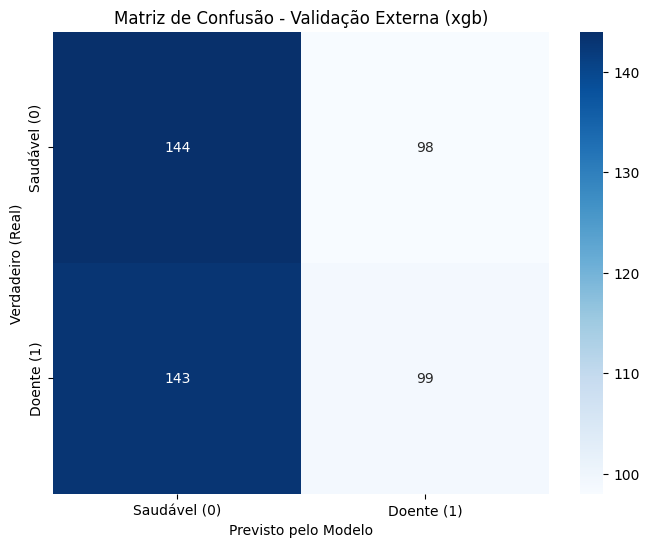

In [11]:
import numpy as np

y_true_shared = np.array(y_shared).ravel()
y_pred_shared = best_xgb.predict(X_shared)
y_prob_shared = best_xgb.predict_proba(X_shared)[:, 1]

# Métricas na Validação Externa
acuracia_shared = accuracy_score(y_true_shared, y_pred_shared)
precisao_shared = precision_score(y_true_shared, y_pred_shared, average='macro', zero_division=0)
recall_shared = recall_score(y_true_shared, y_pred_shared, average='macro', zero_division=0)
f1_shared = f1_score(y_true_shared, y_pred_shared, average='macro', zero_division=0)
mcc_shared = matthews_corrcoef(y_true_shared, y_pred_shared)
auc_shared = roc_auc_score(y_true_shared, y_prob_shared)

print("=== VALIDAÇÃO EXTERNA SHARED ===\n")
print(f"Acurácia: {acuracia_shared:.4f}")
print(f"Precisão: {precisao_shared:.4f}")
print(f"Recall: {recall_shared:.4f}")
print(f"F1-Score: {f1_shared:.4f}")
print(f"MCC: {mcc_shared:.4f}")
print(f"AUC: {auc_shared:.4f}")
print("-" * 50)

# Matriz de Confusão Externa
plt.figure(figsize=(8, 6))
cm_shared = confusion_matrix(y_true_shared, y_pred_shared)
sns.heatmap(cm_shared, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])
plt.title('Matriz de Confusão - Validação Externa (xgb)')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

In [12]:
import pandas as pd

# Mude apenas o nome do modelo aqui
nome_modelo = 'xgb'

arquivo_pred = caminho + 'treino_dengue/saidas/predicoes.csv'
arquivo_proba = caminho + 'treino_dengue/saidas/probabilidades.csv'


# Cria uma lista começando com o nome, o conjunto e depois todas as predições
linha_pred_teste = [nome_modelo, 'teste'] + list(y_pred_best)
linha_pred_val = [nome_modelo, 'validacao'] + list(y_pred_val)
linha_pred_shared = [nome_modelo, 'shared'] + list(y_pred_shared)


# Salva adicionando as linhas embaixo (mode='a') sem cabeçalho
pd.DataFrame([linha_pred_teste, linha_pred_val, linha_pred_shared]).to_csv(arquivo_pred, mode='a', header=False, index=False)


# Probas
linha_proba_teste = [nome_modelo, 'teste'] + list(y_prob_best)
linha_proba_val = [nome_modelo, 'validacao'] + list(y_prob_val)
linha_proba_shared = [nome_modelo, 'shared'] + list(y_prob_shared)

pd.DataFrame([linha_proba_teste, linha_proba_val, linha_proba_shared]).to_csv(arquivo_proba, mode='a', header=False, index=False)

print(f"Linhas do modelo {nome_modelo} adicionadas com sucesso!")

Linhas do modelo xgb adicionadas com sucesso!
